<img src="../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# Kernel SVMs

---

# Imports
---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, train_test_split

from sklearn.svm import SVC, SVR
from sklearn import datasets

# Kernel SVMs on the MNIST data
---

### Hyperparameters of SVMs
SVMs will have two main hyperparameters: `C` and `kernel`.

#### Parameter: `C`
`C` controls how much we regularize the boundary that is fit between classes.
- **If `C` is small**: Stronger regularization --> The SVM accepts some misclassified training points to maintain a wider margin --> More flexible about mistakes 
- **If `C` is large**: Weak regularization --> The SVM tries very hard to classify training points correctly -->  More flexible about mistakes --> Strict about mistakes

<details><summary>As we increase `C`, what happens to our bias-variance tradeoff?</summary>

- If C is small --> Bias increases, variance decreases --> Underfitting
- If C is large --> Bias decreases, variance increases --> Overfitting
    
</details>

#### Parameter: `kernel`
There are several options:
* `linear`, `rbf`, `polynomial`, `sigmoid`, or something custom

**Which do we use?**
- **Quick answer**: As long as it's not the linear kernel, it actually matters surprisingly little!
- **Lazy answer**: Use the RBF kernel, as it's usually best (or no different from other options).
- **Better answer**: It's a model parameter that you're free to gridsearch over!

## Coding with [MNIST Digits Data set](https://en.wikipedia.org/wiki/MNIST_database)

In [2]:
# Load digits
digits = datasets.load_digits()

# Check out data
digits.data

array([[ 0.,  0.,  5., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ..., 10.,  0.,  0.],
       [ 0.,  0.,  0., ..., 16.,  9.,  0.],
       ...,
       [ 0.,  0.,  1., ...,  6.,  0.,  0.],
       [ 0.,  0.,  2., ..., 12.,  0.,  0.],
       [ 0.,  0., 10., ..., 12.,  1.,  0.]], shape=(1797, 64))

In [3]:
# How many observations do we have?
# NOTE: Data is in a NumPy array!



In [4]:
# Check image 55

digits.images[55]

array([[ 0.,  0.,  2., 14., 15.,  5.,  0.,  0.],
       [ 0.,  0., 10., 16., 16., 15.,  1.,  0.],
       [ 0.,  3., 16., 10., 10., 16.,  4.,  0.],
       [ 0.,  5., 16.,  0.,  0., 14.,  6.,  0.],
       [ 0.,  5., 16.,  6.,  0., 12.,  7.,  0.],
       [ 0.,  1., 15., 13.,  4., 13.,  6.,  0.],
       [ 0.,  0., 11., 16., 16., 15.,  0.,  0.],
       [ 0.,  0.,  2., 11., 13.,  4.,  0.,  0.]])

### More about the data:

#### 1. What is the range?

Each pixel has a value between 0 and 16.

| Value | Meaning                    |
| ----- | -------------------------- |
| 0     | Black (no brightness)      |
| 1–5   | Dark gray                  |
| 6–10  | Medium gray                |
| 11–15 | Light gray                 |
| 16    | White (maximum brightness) |

These are grayscale images, so there are no RGB colors.

#### 2. Why are there 64 values?

Each handwritten digit is represented by an 8 × 8 pixel image.

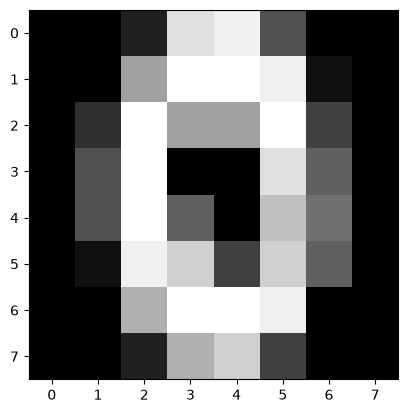

In [5]:
# Generate heatmap of image 55

plt.imshow(
    digits.images[55],
    cmap= 'grey'
)

In [6]:
# What is the actual class?
digits.target[55]


np.int64(0)

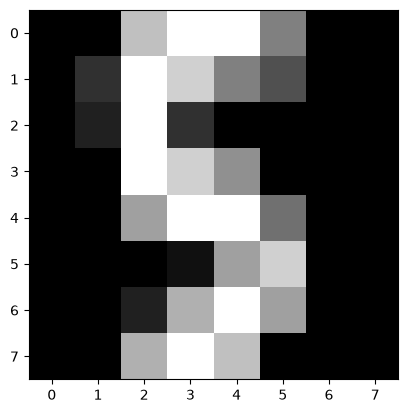

In [7]:
# Generate another heatmap of image 102.
plt.imshow(
    digits.images[102],
    cmap='grey'
)


In [8]:
# What is the actual class?
digits.target[102]

np.int64(5)

In [9]:
# Create X and y

X = digits.data
y = digits.target


In [10]:
# Train/Test Split

X_train, X_test, y_train, y_test = train_test_split (X,y,test_size=0.2,random_state=42, stratify=y)

In [11]:
# Instantiate support vector machine with radial kernel

svm_r = SVC()

In [12]:
# Fit support vector machine to training data.
svm_r.fit(X_train,y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [13]:
# Generate predictions.
y_pred = svm_r.predict(X_test)

y_pred

array([5, 2, 8, 1, 7, 2, 6, 2, 6, 5, 0, 5, 9, 3, 4, 4, 2, 4, 9, 9, 6, 3,
       8, 1, 2, 5, 6, 0, 3, 4, 6, 7, 2, 6, 6, 6, 6, 5, 0, 9, 1, 7, 9, 6,
       5, 7, 5, 2, 7, 5, 0, 1, 5, 5, 3, 2, 4, 0, 0, 2, 7, 5, 6, 1, 3, 7,
       6, 5, 7, 0, 9, 0, 3, 8, 2, 5, 8, 2, 3, 5, 9, 3, 2, 7, 9, 6, 8, 1,
       0, 1, 2, 9, 4, 7, 1, 2, 7, 8, 4, 2, 6, 9, 3, 7, 3, 9, 6, 1, 1, 0,
       9, 2, 1, 6, 3, 4, 8, 7, 1, 0, 0, 4, 6, 5, 8, 2, 8, 1, 3, 0, 0, 8,
       6, 4, 3, 9, 3, 3, 3, 3, 0, 7, 0, 0, 1, 9, 5, 8, 1, 5, 0, 6, 6, 6,
       6, 1, 7, 7, 6, 7, 7, 8, 7, 3, 6, 5, 9, 0, 3, 8, 0, 9, 8, 1, 9, 5,
       9, 5, 8, 9, 9, 7, 9, 1, 9, 5, 4, 7, 3, 0, 4, 9, 7, 7, 5, 6, 5, 8,
       3, 4, 5, 4, 9, 2, 5, 5, 2, 1, 3, 8, 8, 9, 3, 6, 1, 0, 1, 4, 0, 5,
       5, 6, 6, 7, 4, 3, 8, 4, 1, 0, 7, 9, 2, 8, 4, 8, 4, 2, 4, 0, 0, 0,
       2, 6, 7, 0, 4, 5, 2, 2, 9, 0, 4, 6, 8, 2, 3, 9, 2, 3, 0, 6, 8, 7,
       1, 4, 4, 1, 1, 6, 3, 8, 1, 2, 5, 7, 8, 3, 2, 0, 3, 4, 1, 9, 9, 9,
       6, 3, 7, 1, 6, 9, 4, 7, 1, 8, 1, 3, 0, 5, 3,

In [14]:
# Measure performance based on train accuracy.

from sklearn.metrics import accuracy_score

svm_r.score(X_train,y_train)

0.9979123173277662

In [15]:
# Test accuracy?

svm_r.score(X_test,y_test)

0.9916666666666667

<details><summary>Is accuracy the best metric to use here? Why or why not?</summary>

- Accuracy is likely the best metric to use here. Improperly classifying a number is equally bad, no matter what number you incorrectly predict. For example, misclassifying a `4` as a `3` or `5` or `9` is equally bad.
- Many of our other classification metrics (like sensitivity and specificity) don't easily generalize to classification with more than two classes.
</details>

### Now You Try: spend three minutes trying different hyperparameter values. (Feel free to guess and check or use GridSearch/RandomizedSearch!) We'll report our best values in a moment.

In [16]:
# Hint: Try to tune C, kernel and gamma parameters

param_grid = {
    'C' : np.logspace(-2, 3, 6),
    'kernel' : ['linear', 'poly', 'rbf'],
    'gamma' : np.logspace(-4, 1, 6)
}

gs = GridSearchCV(
    estimator= svm_r,
    param_grid= param_grid,
    cv= 3
)

gs.fit(X_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': array([1.e-02...e+02, 1.e+03]), 'gamma': array([1.e-04...e+00, 1.e+01]), 'kernel': ['linear', 'poly', ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls

In [17]:
# What are the best parameters?
gs.best_params_

{'C': np.float64(10.0), 'gamma': np.float64(0.001), 'kernel': 'rbf'}

In [20]:
# What is the best validation score?
gs.score(X_train,y_train)

1.0

In [21]:
# What is the test score?
gs.score(X_test,y_test)

0.9916666666666667

### Support Vector Machines aren't even just for classification!

SVMs can be used for regression problems as well! The main ideas are the same - we still specify a cost tolerance `C` and a kernel - but [it's a bit more complicated](https://www.saedsayad.com/support_vector_machine_reg.htm). (For example, visualizing a "margin" is easier to do when we're separating two classes than when we're trying to predict some continuous outcome.) For this reason, we won't get into the mathematical details of support vector machines applied to regression, but we can instantiate a model using `svr = sklearn.svm.SVR()` and `.fit()`, `.predict()` like we do with all of our other models! Check out the documentation for [regression SVMs here](http://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html).

### Pros and Cons of SVMs

#### Pros
- Exceptional perfomance (historically widely used)
- Effective in high-dimensional data
- Can work with non-linear boundaries
- Fast to compute with most data sets (kernel trick)

#### Cons
- Black box method
- Can be slow on large (tall) data sets

# Conclusions and Takeaways
* SVMs are fantastic models if all you care about is predictive ability.
* They are complete and total black boxes, sorry.
* You must scale your data.
* By the way, doing a kernel SVM with `polynomial kernel degree = 2` has been shown to work really well for NLP data!

# 🧠 (Bonus) The Kernel Trick Example:

This example demonstrates how a **Kernel Function** calculates data relationships in a higher dimension without ever physically transforming the data points.

We will compare two data points, **Point A** and **Point B**, using two different approaches to get the exact same result.

---

#### 📍 The Setup
Imagine a dataset with just **2 features** ($X_1$ and $X_2$):
* **Point A ($x$):** $(2, 3)$
* **Point B ($y$):** $(4, 1)$

We want to find their relationship after mapping them into a **3D polynomial space** using this transformation mapping formula: 
$$\Phi(X_1, X_2) = (X_1^2, \sqrt{2}X_1X_2, X_2^2)$$

---

#### 🚜 Approach 1: High Dimension Creation (The Long Way)
In this approach, the computer physically calculates the new 3D coordinates in memory and then performs a 3D dot product.

**Step 1: Transform Point A into 3D**
$$\Phi(2, 3) = (2^2, \sqrt{2}(2)(3), 3^2) = (4, 6\sqrt{2}, 9)$$

**Step 2: Transform Point B into 3D**
$$\Phi(4, 1) = (4^2, \sqrt{2}(4)(1), 1^2) = (16, 4\sqrt{2}, 1)$$

**Step 3: Calculate the 3D Dot Product**
$$\text{Result} = (4 \times 16) + (6\sqrt{2} \times 4\sqrt{2}) + (9 \times 1)$$
$$\text{Result} = 64 + (24 \times 2) + 9$$
$$\text{Result} = 64 + 48 + 9 = \mathbf{121}$$

*This method forced the computer to allocate RAM for new 3D coordinates and handle complex square-root calculations.*

---

#### ⚡ Approach 2: The Kernel Trick (The Shortcut)
Instead of shifting to 3D, we use a **Polynomial Kernel function** ($K$). This math shortcut promises to deliver the exact same 3D result using only our original 2D numbers:
$$K(x, y) = (x \cdot y)^2$$

**Step 1: Calculate the simple 2D dot product of the original points**
$$x \cdot y = (2 \times 4) + (3 \times 1) = 8 + 3 = 11$$

**Step 2: Apply the Kernel power shortcut**
$$\text{Result} = (11)^2 = \mathbf{121}$$

---

### 🎯 The Takeaway
Both methods yielded the exact same output: **$121$**. 

* **Approach 1** physically expanded the data structure, consuming memory and processing power.
* **Approach 2 (Kernel Trick)** performed a basic 2D calculation, squared the result, and "simulated" the 3D space instantly. This mathematical bypass is why Support Vector Machines scale efficiently to complex, non-linear boundaries.


### 🚀 Scaling Up: The Kernel Trick in 4D Space

This example demonstrates how the Kernel Trick becomes even more valuable as we move into higher dimensions like **4D**, where manually creating features starts to break down.

---

#### 📍 The Setup
We will use the exact same two-dimensional starting points:
* **Point A ($x$):** $(2, 3)$
* **Point B ($y$):** $(4, 1)$

This time, we want to project them into a **4D feature space** using a 3rd-degree polynomial expansion mapping:
$$\Phi(X_1, X_2) = (X_1^3, \sqrt{3}X_1^2X_2, \sqrt{3}X_1X_2^2, X_2^3)$$

---

#### 🚜 Approach 1: High Dimension Creation (The 4D Long Way)
Let's physically transform both 2D points into 4D coordinate arrays.

**Step 1: Transform Point A into 4D**
$$\Phi(2, 3) = (2^3, \sqrt{3}(2^2)(3), \sqrt{3}(2)(3^2), 3^3) = (8, 12\sqrt{3}, 18\sqrt{3}, 27)$$

**Step 2: Transform Point B into 4D**
$$\Phi(4, 1) = (4^3, \sqrt{3}(4^2)(1), \sqrt{3}(4)(1^2), 1^3) = (64, 16\sqrt{3}, 4\sqrt{3}, 1)$$

**Step 3: Calculate the 4D Dot Product**
$$\text{Result} = (8 \times 64) + (12\sqrt{3} \times 16\sqrt{3}) + (18\sqrt{3} \times 4\sqrt{3}) + (27 \times 1)$$
$$\text{Result} = 512 + (192 \times 3) + (72 \times 3) + 27$$
$$\text{Result} = 512 + 576 + 216 + 27 = \mathbf{1331}$$

*Notice how much harder the math became? The computer now has to hold 4 massive numbers per point in its RAM.*

---

#### ⚡ Approach 2: The Kernel Trick (The Identical Shortcut)
To jump straight to the 4D answer, we use the 3rd-degree Polynomial Kernel function:
$$K(x, y) = (x \cdot y)^3$$

**Step 1: Calculate the simple 2D dot product of the original points**
$$x \cdot y = (2 \times 4) + (3 \times 1) = 8 + 3 = 11$$

**Step 2: Apply the Kernel power shortcut (Cube the result)**
$$\text{Result} = (11)^3 = \mathbf{1331}$$

---

### 🎯 The Ultimate Takeaway
Both methods give the exact same answer: **$1331$**.

* In **Approach 1**, the math got noticeably more painful because we added another dimension. If we went to 10D or 100D, calculating the square roots and holding the massive arrays would crash your machine.
* In **Approach 2**, the kernel difficulty remained **exactly the same**. We did the exact same 2D dot product ($11$), and simply changed the exponent from a square ($11^2$) to a cube ($11^3$). 

This proves that the Kernel Trick allows SVMs to compute relationships in **infinite dimensions** (like the RBF kernel does) just as easily as they do in 2D.


## 🧠 (Bonus)  Why Do We Need to Calculate the Relationship Between Points?

In a Support Vector Machine, the model does not actually care about the absolute position of a data point on a map. Instead, it cares entirely about **how similar or different data points are to one another**. 

Mathematically, this relationship is calculated using a **dot product** (or similarity score). Here is why this specific calculation is required to make the model work:

---

#### 1. It Defines the "Support Vectors" and the Margin
An SVM finds the optimal decision boundary by looking at the data points closest to the opposite class (the Support Vectors). 
* To find these critical points, the algorithm must calculate the geometric relationship between every single training point.
* The model measures how much a point pushes against the margin or crosses over to the wrong side. Without calculating these relationships, the model cannot know which points are the "pillars" holding up the boundary.

---

#### 2. It Unlocks the Entire Kernel Trick
Because the SVM math equation *only* looks at data through these point-to-point relationships $(x_i \cdot x_j)$, we can swap out that standard dot product for a Kernel function $K(x_i, x_j)$. 

This is the exact loophole that allows us to curve the axes:
* The model never needs to know the actual $X$ and $Y$ coordinates of a point in 4D, 10D, or infinite dimensions.
* It only ever needs to know the **final relationship score** between them. 

By calculating the relationship directly, we bypass the need to ever build or look at the high-dimensional space itself.

---

